In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt

from neural_recording_chain.frozen_noise import make_frozen_noise
from neural_recording_chain.pyramidal_cell import simulate_pyramidal_cell
from neural_recording_chain.spikes import find_spikes
from neural_recording_chain.electrode import extracellular_potential

dt_ms = 0.05
duration_ms = 60000

# make the input and run the neuron for 60 seconds
input_theory, hidden_state = make_frozen_noise(duration_ms=duration_ms, dt_ms=dt_ms, seed=0)
result = simulate_pyramidal_cell(input_theory, dt_ms=dt_ms)

# the answer key and the clean electrode signal
spike_times, spike_heights = find_spikes(result["v_soma_mV"], result["time_ms"])
v_electrode_uV = extracellular_potential(result["v_soma_mV"], result["v_dend_mV"])

# save everything to one file, so we never have to run this again
os.makedirs("../data/processed", exist_ok=True)
np.savez(
    "../data/processed/simulation_60s.npz",
    time_ms=result["time_ms"],
    v_electrode_uV=v_electrode_uV,
    spike_times=spike_times,
    spike_heights=spike_heights,
)

print("true spikes: ", len(spike_times))
print("tall spikes: ", (spike_heights > 0).sum())
print("small spikes:", (spike_heights <= 0).sum())

true spikes:  543
tall spikes:  210
small spikes: 333


In [3]:
from neural_recording_chain.noise import thermal_noise_uV, background_noise_uV
from neural_recording_chain.detector import detect_spikes
from neural_recording_chain.scoring import score_detection

# load the saved simulation
data = np.load("../data/processed/simulation_60s.npz")
time_ms = data["time_ms"]
v_electrode_uV = data["v_electrode_uV"]
spike_times = data["spike_times"]
spike_heights = data["spike_heights"]

# add the two kinds of noise
n_samples = len(v_electrode_uV)
thermal = thermal_noise_uV(n_samples, dt_ms=0.05)
hum = background_noise_uV(n_samples, dt_ms=0.05)
recording_uV = v_electrode_uV + thermal + hum

# split the answer key into tall and small spikes
tall_times = spike_times[spike_heights > 0]
small_times = spike_times[spike_heights <= 0]

print("tall spikes: ", len(tall_times))
print("small spikes:", len(small_times))

tall spikes:  210
small spikes: 333


3.0 | tall found: 210 | small found: 76 | false alarms: 1197
3.5 | tall found: 210 | small found: 53 | false alarms: 208
4.0 | tall found: 210 | small found: 34 | false alarms: 23
4.5 | tall found: 210 | small found: 26 | false alarms: 1
5.0 | tall found: 209 | small found: 17 | false alarms: 0
5.5 | tall found: 209 | small found: 14 | false alarms: 0
6.0 | tall found: 208 | small found: 7 | false alarms: 0
7.0 | tall found: 202 | small found: 1 | false alarms: 0


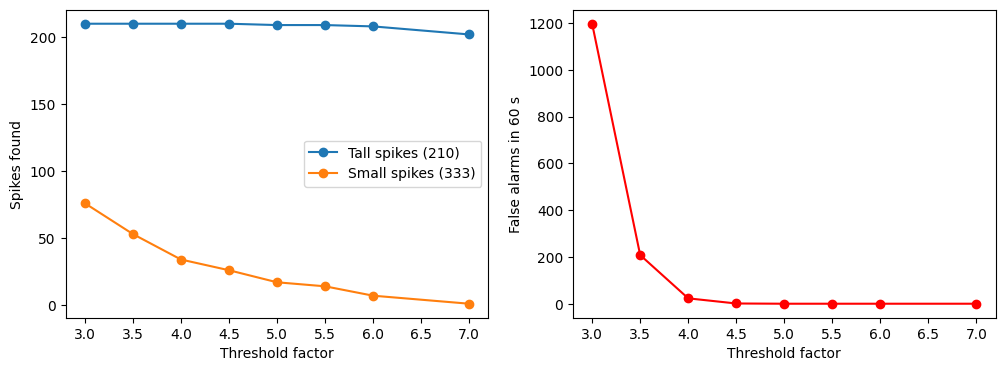

In [6]:
factors = [3.0, 3.5, 4.0, 4.5, 5.0, 5.5, 6.0, 7.0]

tall_found = []
small_found = []
false_alarm_counts = []

for factor in factors:
    detected_times, threshold_uV = detect_spikes(recording_uV, time_ms, threshold_factor=factor)

    tall_hits, tall_misses, unused = score_detection(tall_times, detected_times)
    small_hits, small_misses, unused = score_detection(small_times, detected_times)
    hits, misses, false_alarms = score_detection(spike_times, detected_times)

    tall_found.append(tall_hits)
    small_found.append(small_hits)
    false_alarm_counts.append(false_alarms)

    print(factor, "| tall found:", tall_hits, "| small found:", small_hits, "| false alarms:", false_alarms)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(factors, tall_found, "o-", label="Tall spikes (210)")
axes[0].plot(factors, small_found, "o-", label="Small spikes (333)")
axes[0].set_xlabel("Threshold factor")
axes[0].set_ylabel("Spikes found")
axes[0].legend()

axes[1].plot(factors, false_alarm_counts, "o-", color="red")
axes[1].set_xlabel("Threshold factor")
axes[1].set_ylabel("False alarms in 60 s")

plt.show()

6 bits:  step of 31.25 uV
10 bits: step of 1.95 uV


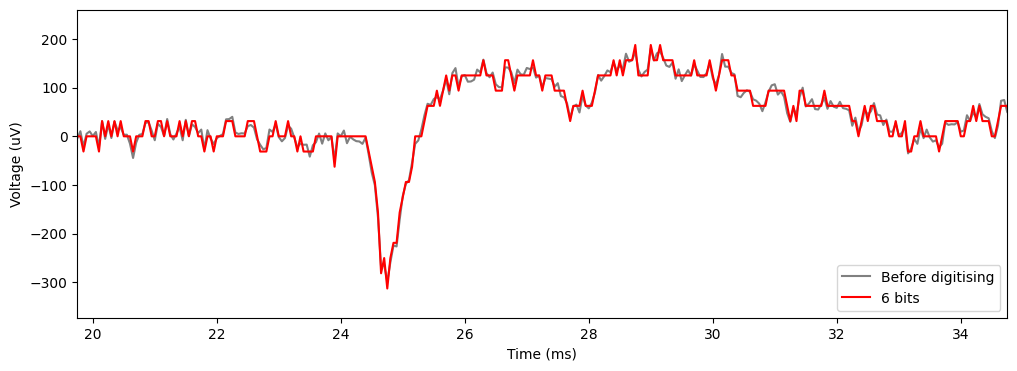

In [7]:
from neural_recording_chain.adc import digitise

coarse_uV, coarse_step = digitise(recording_uV, n_bits=6)
fine_uV, fine_step = digitise(recording_uV, n_bits=10)
print("6 bits:  step of", round(coarse_step, 2), "uV")
print("10 bits: step of", round(fine_step, 2), "uV")

# zoom in around the first tall spike
start_ms = tall_times[0] - 5
end_ms = tall_times[0] + 10

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(time_ms, recording_uV, color="grey", label="Before digitising")
ax.plot(time_ms, coarse_uV, color="red", label="6 bits")
ax.set_xlim(start_ms, end_ms)
ax.set_xlabel("Time (ms)")
ax.set_ylabel("Voltage (uV)")
ax.legend(loc="lower right")
plt.show()

In [8]:
bit_choices = [4, 5, 6, 7, 8, 10, 12]

for n_bits in bit_choices:
    digitised_uV, step_uV = digitise(recording_uV, n_bits=n_bits)
    detected_times, threshold_uV = detect_spikes(digitised_uV, time_ms)

    tall_hits, tall_misses, unused = score_detection(tall_times, detected_times)
    hits, misses, false_alarms = score_detection(spike_times, detected_times)

    print(n_bits, "bits | step:", round(step_uV, 1), "uV | threshold:", round(threshold_uV, 1),
          "uV | tall found:", tall_hits, "| false alarms:", false_alarms)

4 bits | step: 125.0 uV | threshold: 0.0 uV | tall found: 210 | false alarms: 142
5 bits | step: 62.5 uV | threshold: 0.0 uV | tall found: 206 | false alarms: 23117
6 bits | step: 31.2 uV | threshold: 0.0 uV | tall found: 207 | false alarms: 44790
7 bits | step: 15.6 uV | threshold: 104.2 uV | tall found: 209 | false alarms: 0
8 bits | step: 7.8 uV | threshold: 52.1 uV | tall found: 210 | false alarms: 1566
10 bits | step: 2.0 uV | threshold: 78.2 uV | tall found: 210 | false alarms: 1
12 bits | step: 0.5 uV | threshold: 78.2 uV | tall found: 210 | false alarms: 1


In [9]:
print("recording goes from", round(recording_uV.min()), "to", round(recording_uV.max()), "uV")
range_choices = [100, 200, 300, 500, 1000, 5000]
for input_range in range_choices:
    digitised_uV, step_uV = digitise(recording_uV, n_bits=8, input_range_uV=input_range)
    detected_times, threshold_uV = detect_spikes(digitised_uV, time_ms)

    tall_hits, tall_misses, unused = score_detection(tall_times, detected_times)
    hits, misses, false_alarms = score_detection(spike_times, detected_times)

    print("range:", input_range, "uV | step:", round(step_uV, 1), "uV | lowest value:", round(digitised_uV.min()),
          "uV | tall found:", tall_hits, "| false alarms:", false_alarms)

recording goes from -329 to 231 uV
range: 100 uV | step: 0.8 uV | lowest value: -100 uV | tall found: 210 | false alarms: 2
range: 200 uV | step: 1.6 uV | lowest value: -200 uV | tall found: 210 | false alarms: 12
range: 300 uV | step: 2.3 uV | lowest value: -300 uV | tall found: 210 | false alarms: 1
range: 500 uV | step: 3.9 uV | lowest value: -328 uV | tall found: 210 | false alarms: 1
range: 1000 uV | step: 7.8 uV | lowest value: -328 uV | tall found: 210 | false alarms: 1566
range: 5000 uV | step: 39.1 uV | lowest value: -312 uV | tall found: 205 | false alarms: 41029


recording now goes from -1322 to 1203 uV
threshold: 4715.4 uV
detected:  0


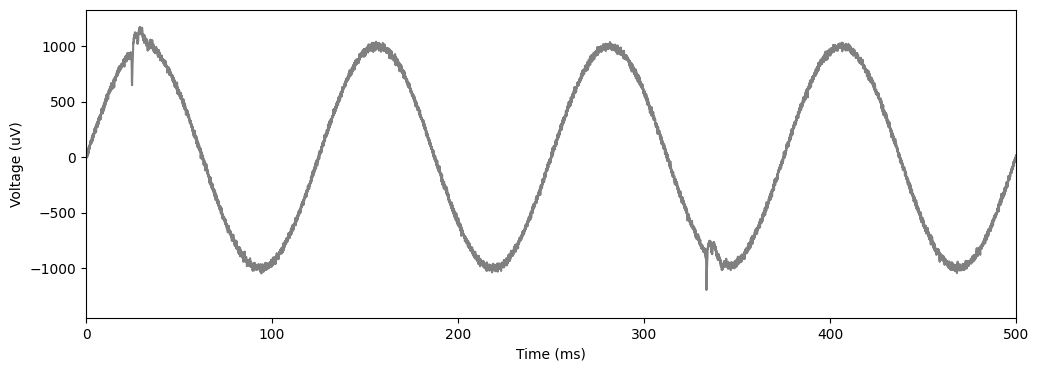

In [10]:
from neural_recording_chain.noise import slow_wave_uV

wave = slow_wave_uV(n_samples, dt_ms=0.05)
recording_with_wave_uV = recording_uV + wave
print("recording now goes from", round(recording_with_wave_uV.min()), "to", round(recording_with_wave_uV.max()), "uV")
detected_times, threshold_uV = detect_spikes(recording_with_wave_uV, time_ms)
print("threshold:", round(threshold_uV, 1), "uV")
print("detected: ", len(detected_times))

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(time_ms, recording_with_wave_uV, color="grey")
ax.set_xlim(0, 500)
ax.set_xlabel("Time (ms)")
ax.set_ylabel("Voltage (uV)")
plt.show()

filtered recording goes from -210 to 180 uV
threshold: 52.2 uV
tall found: 209 | small found: 76 | false alarms: 162


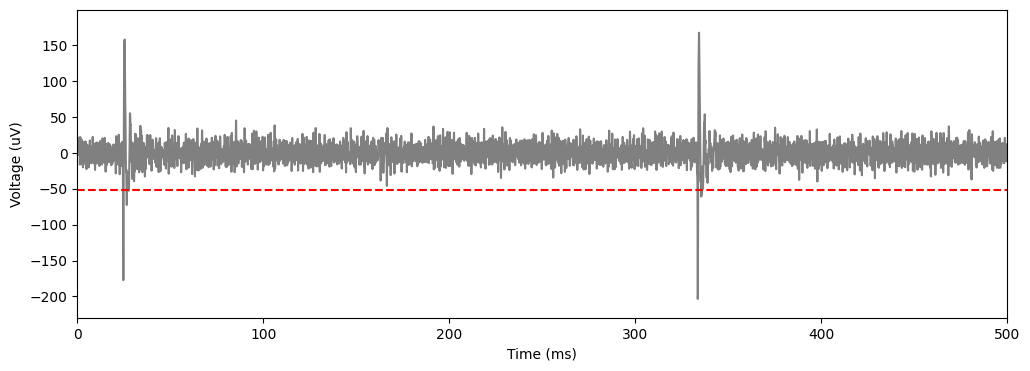

In [13]:
from neural_recording_chain.filter import bandpass_filter

filtered_uV = bandpass_filter(recording_with_wave_uV, dt_ms=0.05)
print("filtered recording goes from", round(filtered_uV.min()), "to", round(filtered_uV.max()), "uV")

detected_times, threshold_uV = detect_spikes(filtered_uV, time_ms)
tall_hits, tall_misses, unused = score_detection(tall_times, detected_times)
small_hits, small_misses, unused = score_detection(small_times, detected_times)
hits, misses, false_alarms = score_detection(spike_times, detected_times)

print("threshold:", round(threshold_uV, 1), "uV")
print("tall found:", tall_hits, "| small found:", small_hits, "| false alarms:", false_alarms)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(time_ms, filtered_uV, color="grey")
ax.axhline(-threshold_uV, color="red", linestyle="--")
ax.set_xlim(0, 500)
ax.set_xlabel("Time (ms)")
ax.set_ylabel("Voltage (uV)")
plt.show()

In [14]:
gap_choices = [1.0, 2.0, 3.0, 5.0, 8.0]
for gap in gap_choices:
    detected_times, threshold_uV = detect_spikes(filtered_uV, time_ms, min_gap_ms=gap)
    tall_hits, tall_misses, unused = score_detection(tall_times, detected_times)
    small_hits, small_misses, unused = score_detection(small_times, detected_times)
    hits, misses, false_alarms = score_detection(spike_times, detected_times)
    print("gap:", gap, "ms | tall found:", tall_hits, "| small found:", small_hits, "| false alarms:", false_alarms)

gap: 1.0 ms | tall found: 209 | small found: 76 | false alarms: 162
gap: 2.0 ms | tall found: 209 | small found: 72 | false alarms: 87
gap: 3.0 ms | tall found: 209 | small found: 43 | false alarms: 5
gap: 5.0 ms | tall found: 196 | small found: 16 | false alarms: 7
gap: 8.0 ms | tall found: 195 | small found: 5 | false alarms: 1


In [15]:
filtered_uV = bandpass_filter(recording_with_wave_uV, dt_ms=0.05)
digitised_uV, step_uV = digitise(filtered_uV, n_bits=8, input_range_uV=500.0)
detected_times, threshold_uV = detect_spikes(digitised_uV, time_ms, threshold_factor=4.5, min_gap_ms=3.0)

tall_hits, tall_misses, unused = score_detection(tall_times, detected_times)
small_hits, small_misses, unused = score_detection(small_times, detected_times)
hits, misses, false_alarms = score_detection(spike_times, detected_times)

print("step:", round(step_uV, 2), "uV | threshold:", round(threshold_uV, 1), "uV")
print("tall found: ", tall_hits, "of", len(tall_times))
print("small found:", small_hits, "of", len(small_times))
print("false alarms:", false_alarms)

step: 3.91 uV | threshold: 52.1 uV
tall found:  209 of 210
small found: 40 of 333
false alarms: 5
